In [145]:
import torch

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
device

device(type='cpu')

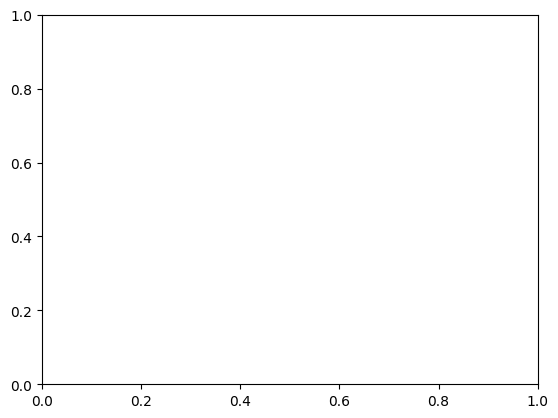

In [146]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots()

plt.show()

In [147]:
from tqdm import tqdm
from sklearn.metrics import f1_score, recall_score, precision_score
import torch.nn.functional as F

losmin = 999

def run_epoch(mdl, opt, loss, dataloader, is_train=True):
    global losmin
    mdl.train(is_train)
    total_loss = 0.0
    
    all_labels = []
    all_predictions = []
    
    with torch.set_grad_enabled(is_train):
        for x, y in tqdm(dataloader):
            x = x.to(device)
            y = y.to(device)
            
            y_pred = mdl(x)
            
            l = loss(y_pred, y)
                
            if (is_train):
                opt.zero_grad()
                l.backward()
                
                opt.step()
            
            
            total_loss += l.item() # loss
            if total_loss / len(dataloader.dataset) < losmin and is_train:
                losmin = total_loss / len(dataloader.dataset)
                torch.save(alex_net_model.state_dict(), 'C:/Users/sasha/Desktop/проекты/YML NN/wrecentalexmod.pth')            
            correct_idx = y.detach().cpu().numpy()
            all_labels.extend(correct_idx)

            predicted_idx = torch.argmax(F.softmax(y_pred.detach(), dim=1), dim=1).cpu().numpy()
            all_predictions.extend(predicted_idx)
    
    return {"Loss": total_loss / len(dataloader.dataset), "F1": f1_score(all_labels, all_predictions, average='macro'), "Recall": recall_score(all_labels, all_predictions, average='macro'), "Precision": precision_score(all_labels, all_predictions, average='macro')}

In [148]:
import numpy as np

def subplot_metrics(metrics, title, num_epochs):
    plt.title(title)
    
    x = np.arange(len(metrics["Train"]))
    
    for lbl, hst in metrics.items():
        plt.plot(x, hst, label=lbl)
    
    plt.grid()
    plt.xticks(np.arange(num_epochs))
    plt.legend()

def plot_metrics(metrics_hist, num_epochs):
    plt.figure(figsize=(16, 8.5))
    
    plt.subplot(2, 2, 1)
    subplot_metrics(metrics_hist["Loss"], f'Loss = {metrics_hist["Loss"]["Train"][-1]}, {metrics_hist["Loss"]["Test"][-1]}', num_epochs)
    
    plt.subplot(2, 2, 2)
    subplot_metrics(metrics_hist["F1"], f'F1 = {metrics_hist["F1"]["Train"][-1]}, {metrics_hist["F1"]["Test"][-1]}', num_epochs)
    
    plt.subplot(2, 2, 3)
    subplot_metrics(metrics_hist["Recall"], f'Recall = {metrics_hist["Recall"]["Train"][-1]}, {metrics_hist["Recall"]["Test"][-1]}', num_epochs)
    
    plt.subplot(2, 2, 4)
    subplot_metrics(metrics_hist["Precision"], f'Precision = {metrics_hist["Precision"]["Train"][-1]}, {metrics_hist["Precision"]["Test"][-1]}', num_epochs)
    
    plt.subplots_adjust(wspace=0.5)
    plt.show()

In [149]:
from IPython.display import clear_output

def run_train_loop(mdl, opt, loss, train_loader, val_loader, num_epochs, is_train=True):
    train_hist = []
    val_hist = []
    metrics_hist = {"Loss": {"Train": [], "Test": []}, "F1":  {"Train": [], "Test": []}, "Recall":  {"Train": [], "Test": []}, "Precision":  {"Train": [], "Test": []}}
    
    for e in range(num_epochs):
        print("Trainin...")
        train_metrics = run_epoch(mdl, opt, loss, train_loader, is_train)
        for key in metrics_hist.keys():
            metrics_hist[key]["Train"].append(train_metrics[key])
        
        print("Validating...")
        val_metrics = run_epoch(mdl, opt, loss, val_loader, is_train=False)
        for key in metrics_hist.keys():
            metrics_hist[key]["Test"].append(val_metrics[key])
        
        clear_output()
        plot_metrics(metrics_hist, num_epochs)

In [ ]:
import torch.nn as nn
from torchsummary import summary


class AlexNet(nn.Module):
    def __init__(self, num_classes: int = 3, dropout: float = 0.5) -> None:
        super().__init__()
        
        self.features = nn.Sequential(
            nn.Conv2d(1, 64, kernel_size=11, stride=4, padding=2),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=3, stride=2),
            nn.Conv2d(64, 192, kernel_size=5, padding=2),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=3, stride=2),
            nn.Conv2d(192, 384, kernel_size=5, padding=1),
            nn.ReLU(inplace=True),
            nn.Conv2d(384, 256, kernel_size=3, padding=1),
            #nn.ReLU(inplace=True),
            #nn.Conv2d(256, 256, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=3, stride=2),
        )
        self.avgpool = nn.AdaptiveAvgPool2d((6, 6))
        self.classifier = nn.Sequential(
            nn.Dropout(p=dropout),
            nn.Linear(256 * 6 * 6, 4096),
            nn.ReLU(inplace=True),
            nn.Dropout(p=dropout),
            nn.ReLU(inplace=True),
            nn.Linear(4096, num_classes),
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        x = self.features(x)
        x = self.avgpool(x)
        x = torch.flatten(x, 1)
        x = self.classifier(x)
        return x


alex_net_model = AlexNet().to(device)
summary(alex_net_model, (1, 256, 256), device="cuda")

In [137]:
from torch.utils.data import Dataset
from torchvision.transforms.v2 import Compose, PILToTensor, ToDtype, Normalize, Grayscale, ToImage, ToTensor, RandomHorizontalFlip
from torch.utils.data import DataLoader
import os
import PIL
from PIL import Image
from torchvision.transforms import ToPILImage
import pandas as pd

class LungsWithMasksDataset(Dataset):
    def __init__(self, csv_file, root_dir, mask_dir, transform=None):
        self.df = pd.read_csv(csv_file)
        self.root_dir = root_dir
        self.mask_dir = mask_dir
        self.transform = transform

    def __len__(self):
        return len(os.listdir(self.root_dir))

    def __getitem__(self, idx):
        img_path = os.path.join(self.root_dir, str('img_' + str(idx) + '.png'))
        image = Image.open(img_path).convert('RGB')
        
        msk_path = os.path.join(self.mask_dir, str('img_' + str(idx) + '.png'))
        mask = Image.open(msk_path).convert('RGB')
        
        to_tensor = ToTensor()
        
        image = to_tensor(image)
        mask = to_tensor(mask)
        
        image = image * mask

        label = self.df.iloc[idx, 1]

        if self.transform:
            to_pil = ToPILImage()
            image = to_pil(image)
            
            image = self.transform(image)

        return image, label


transform = Compose([
    Grayscale(), # transforms.ColorJitter(1)
#     RandomResizedCrop(size=(224, 224), antialias=True, scale=(0.8, 1.0)),
#     RandomRotation(degrees=(-10, 10)),
    ToTensor()
])
data_train = LungsWithMasksDataset(csv_file='C:/Users/sasha/Downloads/ml-intensive-yandex-autumn-2023/data/train_answers.csv', root_dir='C:/Users/sasha/Downloads/ml-intensive-yandex-autumn-2023/data/train_images', mask_dir='C:/Users/sasha/Downloads/ml-intensive-yandex-autumn-2023/data/train_lung_masks', transform=transform)

In [138]:
data_train[0][0].shape

C:\Users\sasha\AppData\Local\Programs\Python\Python310\lib\site-packages\torchvision\transforms\v2\_deprecated.py:43: UserWarning: The transform `ToTensor()` is deprecated and will be removed in a future release. Instead, please use `v2.Compose([v2.ToImage(), v2.ToDtype(torch.float32, scale=True)])`.
  warnings.warn(


torch.Size([1, 256, 256])

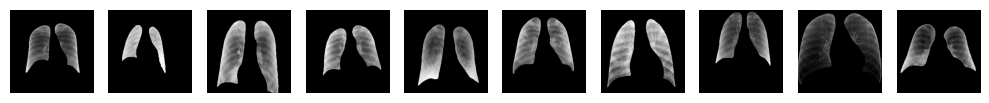

In [139]:
import torchshow as ts
x = torch.stack([data_train[i][0] for i in range(10)]).to(device)
ts.show(x, nrows=1, figsize=(10, 2))

In [140]:
import torch.utils.data
from torch.utils.data import random_split


num_samples = len(data_train)
num_test = int(0.2 * num_samples)
num_train = num_samples - num_test

train_subset, test_subset = random_split(data_train, [num_train, num_test])

print(f'Train len: {len(train_subset)} \n Test len: {len(test_subset)}')

Train len: 21600 
 Test len: 5400


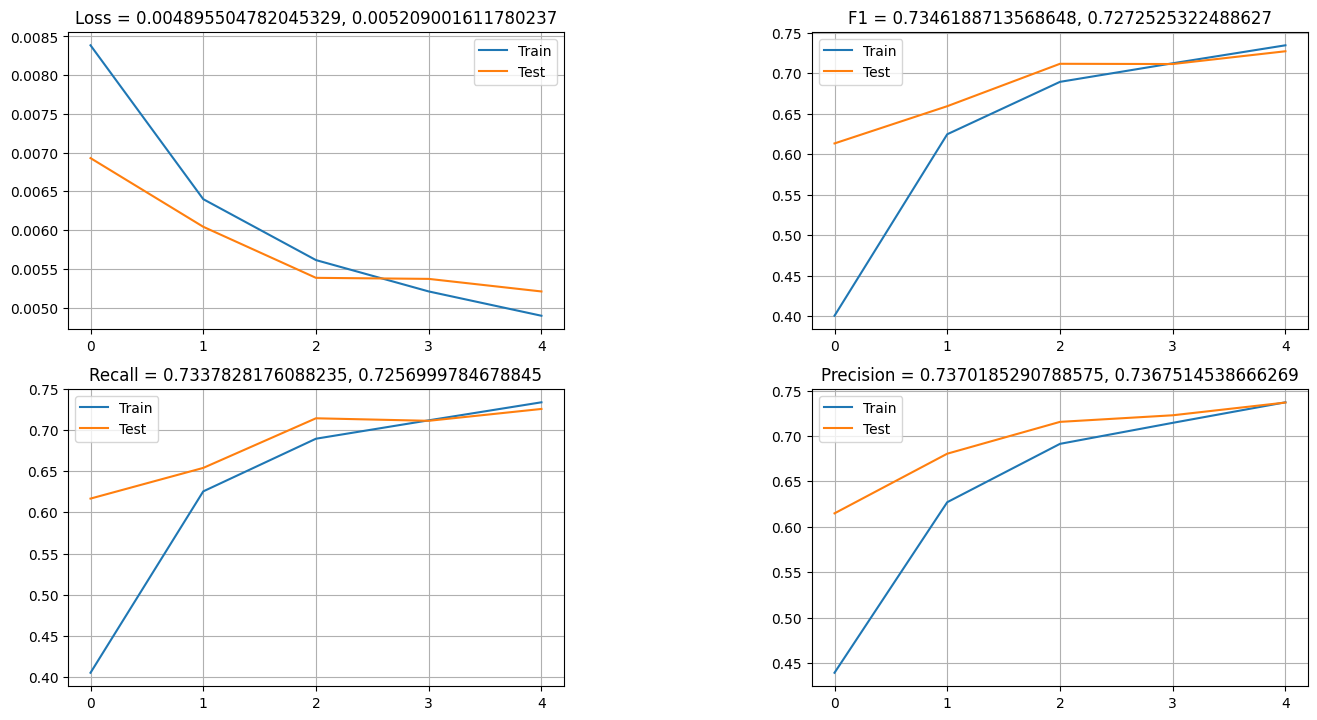

In [86]:
batch_size = 128
num_epochs = 5 # 20

train_loader = DataLoader(train_subset, batch_size=batch_size)
valid_loader = DataLoader(test_subset, batch_size=batch_size)

optimizer = torch.optim.Adam(alex_net_model.parameters())
criterion = torch.nn.CrossEntropyLoss()


run_train_loop(alex_net_model, optimizer, criterion,
               train_loader, valid_loader, num_epochs)

In [127]:
alex_net_model.load_state_dict(torch.load('C:/Users/sasha/Desktop/проекты/YML NN/wrecentalexnet.pth'))
print(type(alex_net_model))


RuntimeError: Error(s) in loading state_dict for AlexNet:
	Missing key(s) in state_dict: "classifier.5.weight", "classifier.5.bias". 
	Unexpected key(s) in state_dict: "classifier.6.weight", "classifier.6.bias", "classifier.4.weight", "classifier.4.bias". 
	size mismatch for features.6.weight: copying a param with shape torch.Size([384, 192, 3, 3]) from checkpoint, the shape in current model is torch.Size([384, 192, 5, 5]).

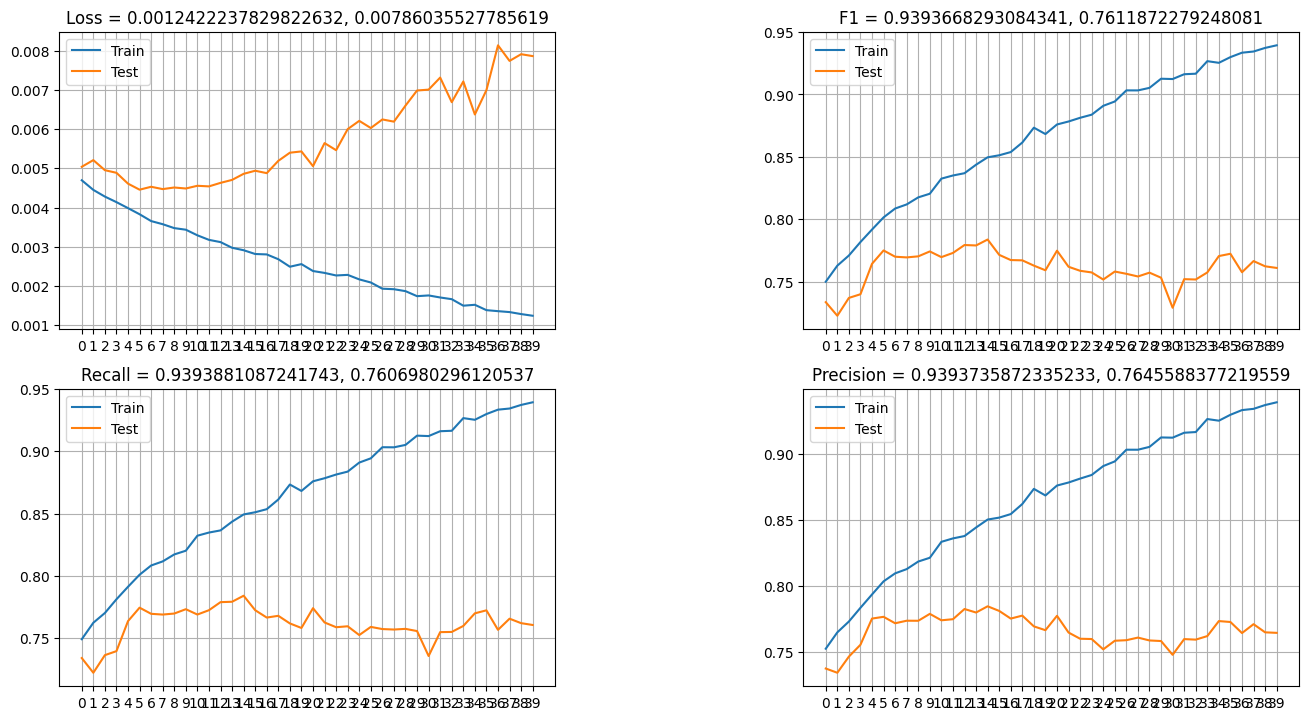

In [110]:
batch_size = 128
num_epochs = 40 # 20

train_loader = DataLoader(train_subset, batch_size=batch_size)
valid_loader = DataLoader(test_subset, batch_size=batch_size)

optimizer = torch.optim.Adam(alex_net_model.parameters())
criterion = torch.nn.CrossEntropyLoss()


run_train_loop(alex_net_model, optimizer, criterion,
               train_loader, valid_loader, num_epochs)

In [88]:
torch.save(alex_net_model.state_dict(), 'C:/Users/sasha/Desktop/проекты/YML NN/wlastalexnet.pth')  

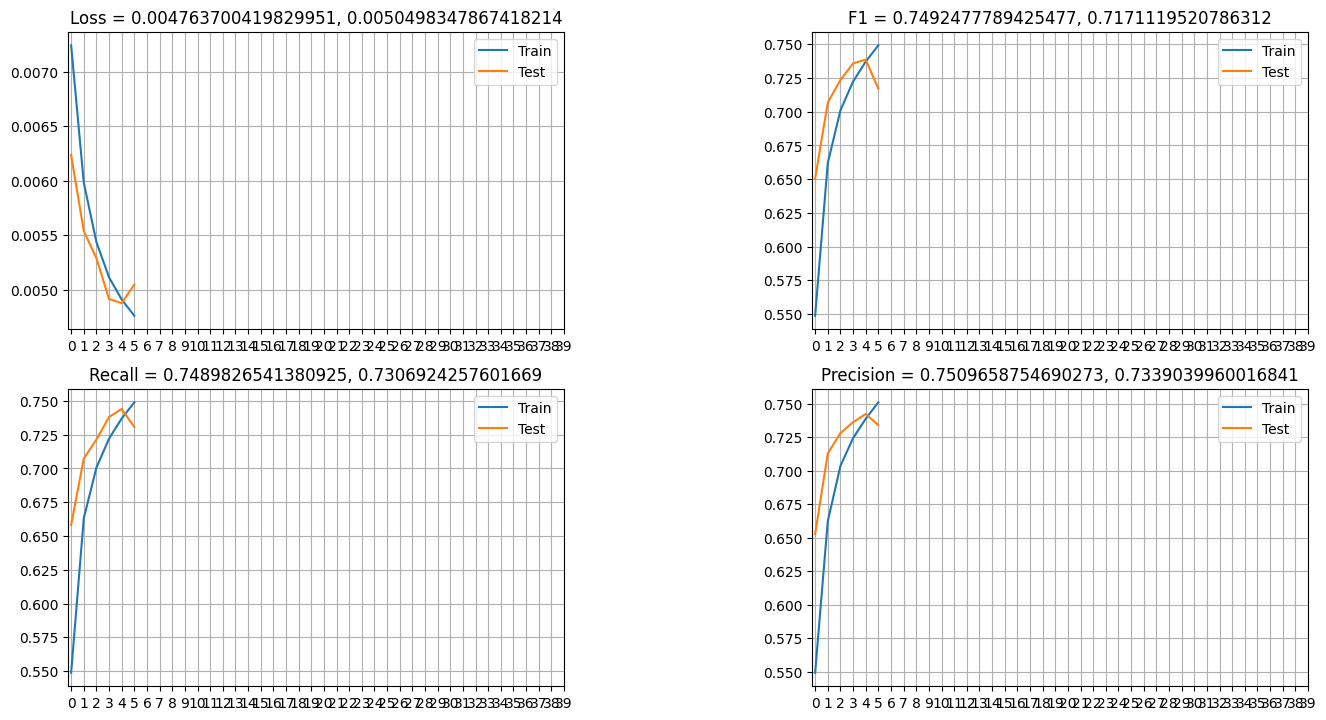

Trainin...


  0%|                                                                                          | 0/169 [00:00<?, ?it/s]C:\Users\sasha\AppData\Local\Programs\Python\Python310\lib\site-packages\torchvision\transforms\v2\_deprecated.py:43: UserWarning: The transform `ToTensor()` is deprecated and will be removed in a future release. Instead, please use `v2.Compose([v2.ToImage(), v2.ToDtype(torch.float32, scale=True)])`.
  warnings.warn(
 50%|████████████████████████████████████████▋                                        | 85/169 [06:36<06:31,  4.66s/it]


KeyboardInterrupt: 

In [136]:
batch_size = 128
num_epochs = 40 # 20

train_loader = DataLoader(train_subset, batch_size=batch_size)
valid_loader = DataLoader(test_subset, batch_size=batch_size)

optimizer = torch.optim.Adam(alex_net_model.parameters())
criterion = torch.nn.CrossEntropyLoss()


run_train_loop(alex_net_model, optimizer, criterion,
               train_loader, valid_loader, num_epochs)

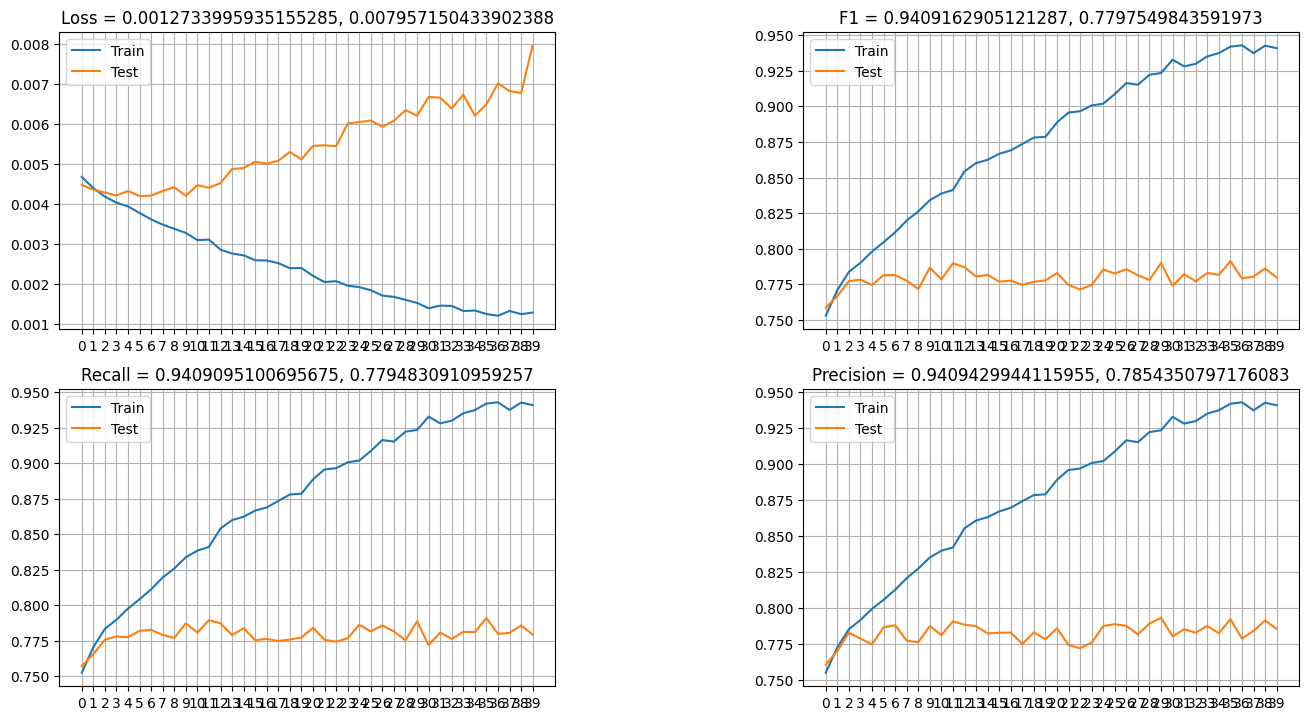

In [142]:
alex_net_model.load_state_dict(torch.load('C:/Users/sasha/Desktop/проекты/YML NN/wrecentalexmod.pth'))

batch_size = 128
num_epochs = 40 # 20

train_loader = DataLoader(train_subset, batch_size=batch_size)
valid_loader = DataLoader(test_subset, batch_size=batch_size)

optimizer = torch.optim.Adam(alex_net_model.parameters())
criterion = torch.nn.CrossEntropyLoss()


run_train_loop(alex_net_model, optimizer, criterion,
               train_loader, valid_loader, num_epochs)

In [143]:
torch.save(alex_net_model.state_dict(), 'C:/Users/sasha/Desktop/проекты/YML NN/w21121248.pth')  

In [193]:
from torch.utils.data import Dataset
from torchvision.transforms.v2 import Compose, PILToTensor, ToDtype, Normalize
from torchvision import datasets, transforms
import os
from PIL import Image
import pandas as pd


class CustomDataset(Dataset):
    def __init__(self, root_dir, transform=None):
        self.root_dir = root_dir
        self.transform = transform

    def __len__(self):
        return len(os.listdir(self.root_dir))

    def __getitem__(self, idx):
        img_path = os.path.join(self.root_dir, str('img_' + str(idx) + '.png'))
        image = Image.open(img_path).convert('RGB')
                
        if self.transform:
            image = self.transform(image)

        return image


transform = transforms.Compose([
    transforms.Grayscale(),
    transforms.ToTensor()
])

data_main_test = CustomDataset(root_dir='C:/Users/sasha/Downloads/ml-intensive-yandex-autumn-2023/data/test_images', transform=transform)
test_loader = DataLoader(data_main_test)


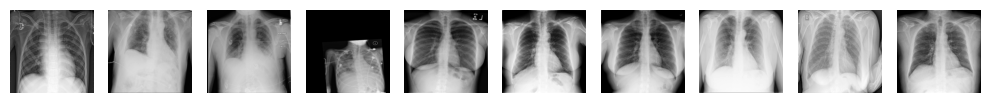

In [194]:
import torchshow as ts
x = torch.stack([data_main_test[i] for i in range(10)]).to(device)
ts.show(x, nrows=1, figsize=(10, 2))

In [243]:
from torch import nn
import torch
import torchvision.transforms.functional as TF


class DoubleConv(nn.Module):
    def __init__(self, in_channels, out_channels, kernal_size, strides, padding):
        super(DoubleConv, self).__init__()
        self.conv = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, kernal_size, strides, padding, bias=False),
            nn.BatchNorm2d(num_features=out_channels),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_channels, out_channels, kernal_size, strides, padding, bias=False),
            nn.BatchNorm2d(num_features=out_channels),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.conv(x)


class UNet(nn.Module):
    def __init__(self, in_channels, num_segmentations=1, features=[64, 128, 256, 512]):
        super(UNet, self).__init__()
        self.ups = nn.ModuleList()
        self.downs = nn.ModuleList()
        self.bottleneck = DoubleConv(
            in_channels=features[-1],
            out_channels=features[-1]*2,
            kernal_size=3,
            strides=1,
            padding=1
        )
        self.output = nn.Conv2d(
            in_channels=features[0],
            out_channels=num_segmentations,
            kernel_size=1
        )
        self.pool = nn.MaxPool2d(kernel_size=2, stride=2)

        in_channels_iter = in_channels
        for feature in features:
            self.downs.append(DoubleConv(
                    in_channels=in_channels_iter,
                    out_channels=feature,
                    kernal_size=3,
                    strides=1,
                    padding=1
                ))
            in_channels_iter = feature

        for feature in reversed(features):
            up = nn.Sequential(
                nn.ConvTranspose2d(
                    in_channels=feature*2,
                    out_channels=feature,
                    kernel_size=2,
                    stride=2,
                    padding=0
                ),
                DoubleConv(
                    in_channels=feature*2,
                    out_channels=feature,
                    kernal_size=3,
                    padding=1,
                    strides=1
                )
            )

            self.ups.append(up)

    def forward(self, x):
        skip_connections = []
        for down in self.downs:
            x = down(x)
            skip_connections.append(x)
            x = self.pool(x)

        x = self.bottleneck(x)
        skip_connections = skip_connections[::-1]

        for i in range(len(self.ups)):
            x = self.ups[i][0](x) # Pass through ConvTranspose first

            skip_connection = skip_connections[i]

            # If the height and width of output tensor and skip connection
            # is not same then resize the tensor
            if x.shape != skip_connection.shape:
                x = TF.resize(x, size=skip_connection.shape[2:])

            # Concat the output tensor with skip connection
            concat_x = torch.cat((skip_connection, x), dim=1)

            # Pass the concatinated tensor through DoubleCOnv
            x = self.ups[i][1](concat_x)
        x = self.output(x)   
        x1 = torch.clone(x)
        x[x < torch.mean(x1)] = 0
        x[x >= torch.mean(x1)] = 1

        return x[0]

In [244]:
model = UNet(in_channels=1).to(device)

In [245]:
from torchsummary import summary
import torch


summary(model, (1, 256, 256), device='cpu')

----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Conv2d-1         [-1, 64, 256, 256]             576
       BatchNorm2d-2         [-1, 64, 256, 256]             128
              ReLU-3         [-1, 64, 256, 256]               0
            Conv2d-4         [-1, 64, 256, 256]          36,864
       BatchNorm2d-5         [-1, 64, 256, 256]             128
              ReLU-6         [-1, 64, 256, 256]               0
        DoubleConv-7         [-1, 64, 256, 256]               0
         MaxPool2d-8         [-1, 64, 128, 128]               0
            Conv2d-9        [-1, 128, 128, 128]          73,728
      BatchNorm2d-10        [-1, 128, 128, 128]             256
             ReLU-11        [-1, 128, 128, 128]               0
           Conv2d-12        [-1, 128, 128, 128]         147,456
      BatchNorm2d-13        [-1, 128, 128, 128]             256
             ReLU-14        [-1, 128, 1

In [246]:
model.load_state_dict(torch.load('C:/Users/sasha/Downloads/Telegram Desktop/weights (2).pth', map_location=torch.device('cpu')))


<All keys matched successfully>

torch.Size([5, 1, 256, 256])
torch.Size([5, 1, 256, 256])


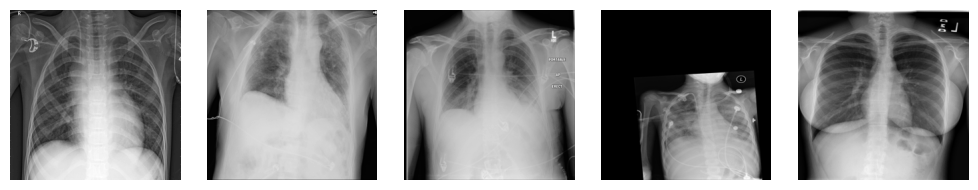

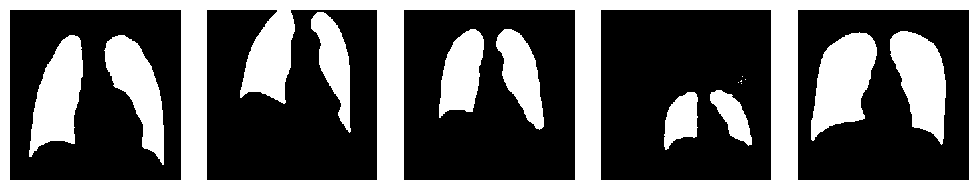

In [250]:
model.eval()
c = 0
outputs = []
inputs = []
with torch.no_grad():
    for i in range(5):#len(data_main_test)):
        inp = data_main_test[i].clone().detach()
        inputs.append(inp)

        inp = inp.unsqueeze(0)
        inp = inp.to(device)
        
        output = model(inp)
        outputs.append(output)

        
import torchshow as ts
x = torch.stack([inputs[i] for i in range(5)])
y = torch.stack([outputs[i] for i in range(5)])
print(x.shape)
print(y.shape)
ts.show(x, nrows=1, figsize=(10, 2))  # pictures from test_images
ts.show(y, nrows=1, figsize=(10, 2))  # masks from this model

In [254]:
data = []

alex_net_model.eval()
model.eval()

with torch.no_grad():
    for i in range(len(data_main_test)):
        inp = data_main_test[i].clone().detach()
        inp = inp.unsqueeze(0)
        inp = inp.to(device)
        mask = model(inp)
        img = inp * mask[0]
        output = alex_net_model(img)
        
        
        predicted_id =  torch.argmax(F.softmax(output, dim=1)).item()
        data.append([i, predicted_id])
        print(i)
        

df = pd.DataFrame(data)
 
file_path = 'answers.csv'

df.columns = ['id', 'target_feature']
df.to_csv(file_path, index=False, header=True)

print(f'CSV file saved to: {file_path}')


5938
5939
5940
5941
5942
5943
5944
5945
5946
5947
5948
5949
5950
5951
5952
5953
5954
5955
5956
5957
5958
5959
5960
5961
5962
5963
5964
5965
5966
5967
5968
5969
5970
5971
5972
5973
5974
5975
5976
5977
5978
5979
5980
5981
5982
5983
5984
5985
5986
5987
5988
5989
5990
5991
5992
5993
5994
5995
5996
5997
5998
5999
6000
6001
6002
6003
6004
6005
6006
6007
6008
6009
6010
6011
6012
6013
6014
6015
6016
6017
6018
6019
6020
6021
6022
6023
6024
6025
6026
6027
6028
6029
6030
6031
6032
6033
6034
6035
6036
6037
6038
6039
6040
6041
6042
6043
6044
6045
6046
6047
6048
6049
6050
6051
6052
6053
6054
6055
6056
6057
6058
6059
6060
6061
6062
6063
6064
6065
6066
6067
6068
6069
6070
6071
6072
6073
6074
6075
6076
6077
6078
6079
6080
6081
6082
6083
6084
6085
6086
6087
6088
6089
6090
6091
6092
6093
6094
6095
6096
6097
6098
6099
6100
6101
6102
6103
6104
6105
6106
6107
6108
6109
6110
6111
6112
6113
6114
6115
6116
6117
6118
6119
6120
6121
6122
6123
6124
6125
6126
6127
6128
6129
6130
6131
6132
6133
6134
6135
6136
6137
